In [4]:
# Part 1

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/Users/Dejmen/Desktop/Ironhack/week5/Day1/amz_uk_price_prediction_dataset.csv')

In [5]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [6]:
df.shape

(2443651, 9)

In [7]:
df.tail()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing
2443650,2828593,B08P3W9B3T,RIDEX CJ223 Motorcycle Motorbike Jacket Armour...,4.5,34,53.99,False,0,Motorbike Clothing


In [8]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

In [9]:
df.isnull().sum()

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In [12]:
# Frequency tables


category_counts = df['category'].value_counts().reset_index()
category_counts.columns = ['Category', 'Count']

top_5_categories = category_counts.head(5)
print("Top 5 Product Categories:")
print(top_5_categories)

Top 5 Product Categories:
                                 Category   Count
0                       Sports & Outdoors  836265
1                                  Beauty   19312
2  Handmade Clothing, Shoes & Accessories   19229
3                             Bath & Body   19092
4                          Birthday Gifts   18978


/var/folders/74/2xg39v_50tv7vj24jw0r0b800000gn/T/ipykernel_94949/815214702.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=category_counts.head(10), x='Count', y='Category', palette='viridis')


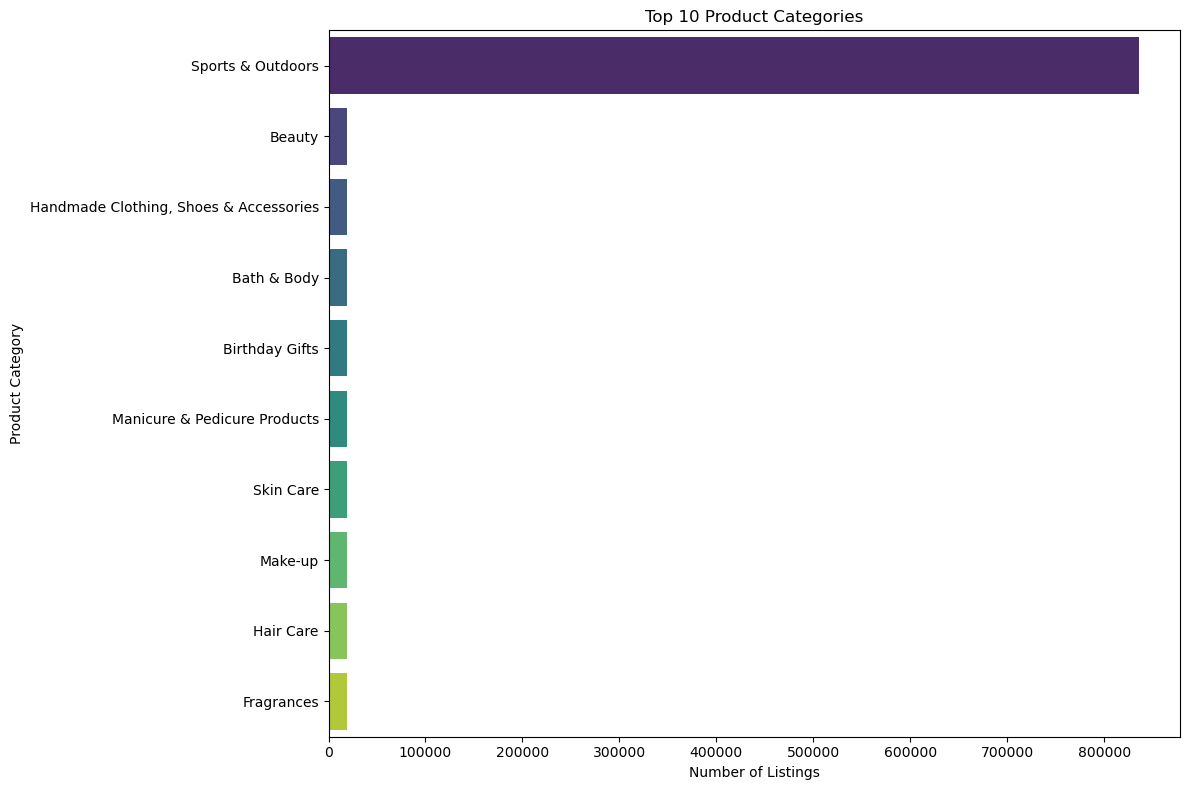

In [15]:
# Visualisations

plt.figure(figsize=(12, 8))
sns.barplot(data=category_counts.head(10), x='Count', y='Category', palette='viridis')
plt.title('Top 10 Product Categories')
plt.xlabel('Number of Listings')
plt.ylabel('Product Category')
plt.tight_layout()
plt.show()

<Figure size 1000x1000 with 0 Axes>

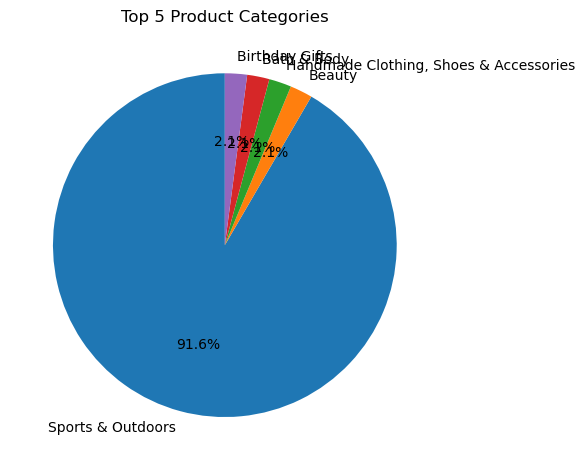

In [17]:
plt.figure(figsize=(10, 10))
top_5_categories.plot.pie(y='Count', labels=top_5_categories['Category'], 
                         autopct='%1.1f%%', startangle=90, legend=False)
plt.title('Top 5 Product Categories')
plt.ylabel('')
plt.tight_layout()
plt.show()

In [21]:
# Part 2
# 1
mean_price = df['price'].mean()
median_price = df['price'].median()
mode_price = df['price'].mode()[0]

mean_price
median_price
mode_price

9.99

In [22]:
# 2 Measures of Dispersion:
price_var = df['price'].var()
price_std = df['price'].std()
price_range = df['price'].max() - df['price'].min()
price_iqr = df['price'].quantile(0.75) - df['price'].quantile(0.25)

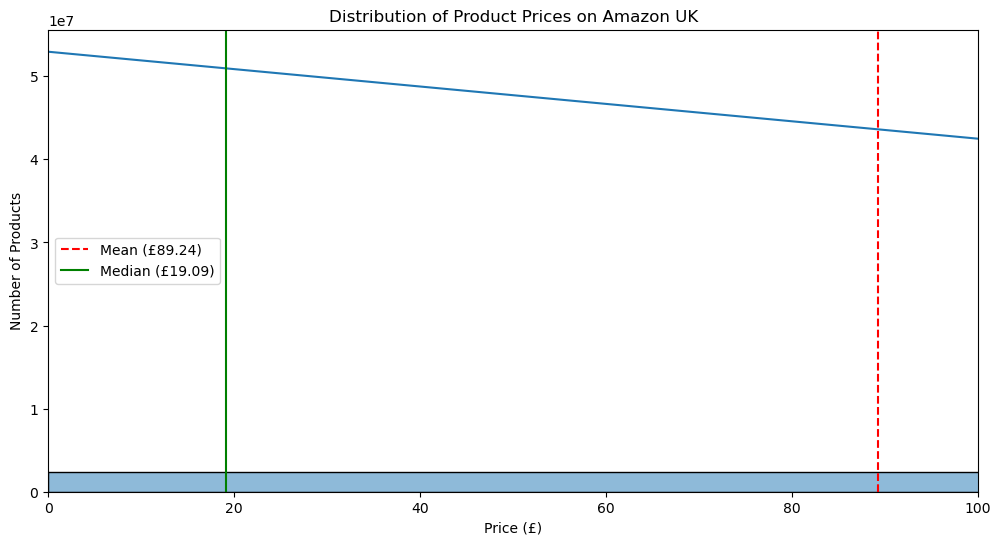

In [24]:
# 3 Visualisations

plt.figure(figsize=(12, 6))
sns.histplot(df['price'], bins=50, kde=True)
plt.title('Distribution of Product Prices on Amazon UK')
plt.xlabel('Price £')
plt.ylabel('Number of Products')
plt.xlim(0, 100) 
plt.axvline(mean_price, color='r', linestyle='--', label=f'Mean (£{mean_price:.2f})')
plt.axvline(median_price, color='g', linestyle='-', label=f'Median (£{median_price:.2f})')
plt.legend()
plt.show()

In [32]:
# Part 3

# 1
mean_rating = df['stars'].mean()
median_rating = df['stars'].median()
mode_rating = df['stars'].mode()[0]  

print("Rating Centrality Measures:")
print(f"Mean rating: {mean_rating:.2f}/5")
print(f"Median rating: {median_rating:.2f}/5")
print(f"Mode rating: {mode_rating:.2f}/5")

# Interpretation
print("Customer Rating Trends:")
print(f"The average product rating is {mean_rating:.2f}, with most products rated {mode_rating}/5")
if mean_rating > 3.5:
    print("Customers generally rate products positively on Amazon UK")
else:
    print("Customer ratings show room for improvement")

Rating Centrality Measures:
Mean rating: 2.15/5
Median rating: 0.00/5
Mode rating: 0.00/5
Customer Rating Trends:
The average product rating is 2.15, with most products rated 0.0/5
Customer ratings show room for improvement


In [34]:
# 2 Dispersion
rating_std = df['stars'].std()
rating_iqr = df['stars'].quantile(0.75) - df['stars'].quantile(0.25)

print("Rating Dispersion Measures:")
print(f"Standard deviation: {rating_std:.2f}")
print(f"Interquartile range (IQR): {rating_iqr:.2f}")



Rating Dispersion Measures:
Standard deviation: 2.19
Interquartile range (IQR): 4.40


In [ ]:
# 3 Distribution


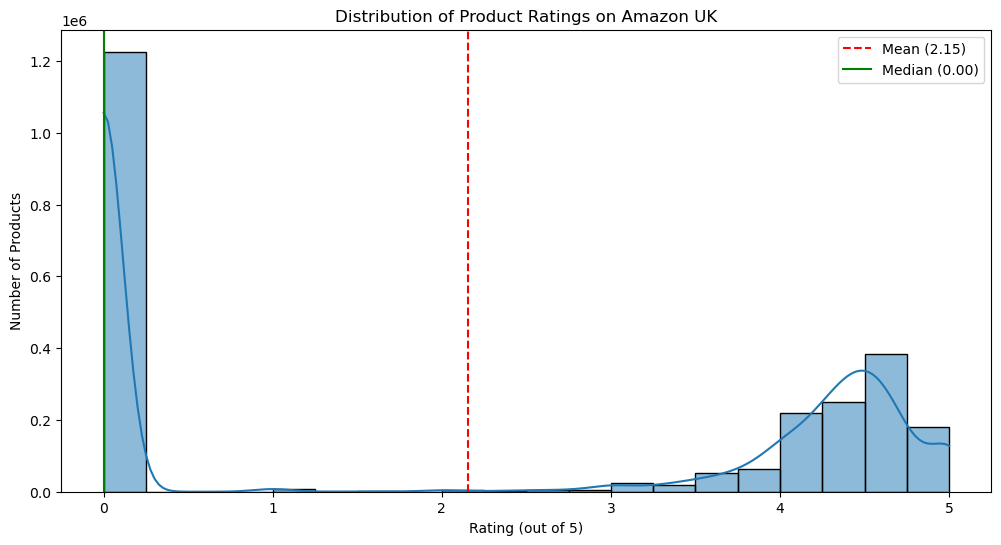

In [35]:
# 4 

plt.figure(figsize=(12, 6))
sns.histplot(df['stars'], bins=20, kde=True)
plt.title('Distribution of Product Ratings on Amazon UK')
plt.xlabel('Rating (out of 5)')
plt.ylabel('Number of Products')
plt.axvline(mean_rating, color='r', linestyle='--', label=f'Mean ({mean_rating:.2f})')
plt.axvline(median_rating, color='g', linestyle='-', label=f'Median ({median_rating:.2f})')
plt.legend()
plt.show()
